# NewJFactory

This notebook shows how to compute J/D-Factor maps with the angular sector method. The main idea is to integrate over an angular region assigned to each pixel, instead of evaluating only the line of sight through its center.

this notebook can be used with [Júlia's branch](https://github.com/juliagouveamamprim/gammapy/tree/refactor-jfactory-los-integration).

In [44]:
import numpy as np
from scipy import integrate

import astropy.units as u
import astropy.constants as const
from astropy.coordinates import SkyCoord, angular_separation

from regions import CircleSkyRegion

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from gammapy.astro.darkmatter import NFWProfile, EinastoProfile
from gammapy.maps import WcsGeom, WcsNDMap
from gammapy.modeling.models import TemplateSpatialModel, SkyModel
from gammapy.astro.darkmatter import DarkMatterSpectralModel

## Integration and map boundaries

The D/J-factor is computed by integrating along the line of sight (LOS) in the observer’s reference frame. The dark matter (DM) density profile is expressed in this frame by transforming from spherical coordinates centered on the DM halo to spherical coordinates centered on the observer. Each WCS pixel is approximated by an angular sector. The method is based on [D Ambrosino et al 2025 J. Phys.: Conf. Ser. 3053 012021](https://iopscience.iop.org/article/10.1088/1742-6596/3053/1/012021).

The method is implemented in a `NewJfactory` class, which could replace or complement the existing Gammapy implementation. It requires:

1. `profile`: `gammapy.astro.darkmatter.DMProfile`;
2. `center_dis`: distance of the DM halo center from the observer;
3. `r_min` and `r_max`: lower and upper integration bound along the LOS;
4. `geom`: `gammapy.maps.WcsGeom` used to obtain the bin size `binsz`, and the pixel area `omega` (taken from the central map pixel) and the angular separation of every pixel from the DM halo center if maps are needed. it is optional;
5. `lon_0` and `lat_0`: halo center position in the coordinate frame of `geom`. If omitted, the center of `geom` is used

The class provides four methods:

- `compute_jfactor` computes the J/D-Factor by evaluating the integral over the specified bounds, it does not require a map. It requires:
  1. `factor`: 1 for decay (D-Factor) and 2 for annihilation (J-Factor);
  2. `phi_min` and `phi_max`: integration boundaries in the `phi` variable;
  3. `theta`: azimuthal angular interval.

- `compute_jfactor_pixel` obtains the angular boundaries for one pixel of `geom`, then calls `compute_jfactor`. It requires:
  1. `factor`: 1 for decay (D-Factor) and 2 for annihilation (J-Factor);
  2. Pixel indices `x` and `y`.

- `compute_jfactor_map` repeats the same calculation for all pixels in `geom` and returns a `WcsNDMap` that can be used as the DM source spatial model.


In [2]:
class NewJFactory:
    def __init__(
        self, profile, center_dis, r_min, r_max,
        geom=None, lon_0=None, lat_0=None
    ):
        self.profile = profile
        self.center_dis = center_dis
        self.r_min = r_min
        self.r_max = r_max
        self.geom = geom

        if (lon_0 is None) != (lat_0 is None):
            raise ValueError("Give both lon_0 and lat_0.")

        if geom is not None:
            self.lon_0 = geom.center_coord[0] if lon_0 is None else lon_0
            self.lat_0 = geom.center_coord[1] if lat_0 is None else lat_0

            # Pixel width and solid angle
            self.binsz = (geom.width[0] / geom.npix[0])[0].to("rad")
            self.omega = geom.solid_angle()[
                int(geom.npix[1][0] / 2), int(geom.npix[0][0] / 2)
            ].to("sr")

    def compute_jfactor(self, factor, phi_min, phi_max, theta):
        """Compute the J-Factor (factor=2) or D-Factor (factor=1)."""
        if factor not in (1, 2):
            raise ValueError("factor must be 1 (decay) or 2 (annihilation)")

        # Distance and integration boundaries in cm and rad
        center_dis = self.center_dis.to_value("cm")
        r_min = self.r_min.to_value("cm")
        r_max = self.r_max.to_value("cm")
        phi_min = phi_min.to_value("rad")
        phi_max = phi_max.to_value("rad")
        theta = theta.to_value("rad")

        # Density profile evaluated at the radius from the DM halo center
        def integrand(r, phi):
            radius = np.sqrt(
                r**2 + center_dis**2 - 2*r*center_dis*np.cos(phi)
            ) * u.cm
            rho = self.profile(radius).to_value("GeV / cm3")
            return np.sin(phi) * rho**factor

        integral = integrate.nquad(
            integrand, [[r_min, r_max], [phi_min, phi_max]]
        )

        # Integral * DTheta
        jfact = (
            theta * integral[0]
            * u.GeV**factor * u.cm**(-3 * factor + 1)
        )
        return jfact

    def compute_jfactor_pixel(self, factor, x, y):
        """Compute the J-Factor or D-Factor for one pixel of geom."""
        if self.geom is None:
            raise ValueError("Define geom to compute a map pixel.")

        ny, nx = self.geom.data_shape
        if not (0 <= x < nx and 0 <= y < ny):
            raise IndexError("Pixel outside geom.")

        # Pixel coordinates in the frame of the map
        coord = self.geom.get_coord()
        lon = u.Quantity(coord.lon[y, x], u.deg)
        lat = u.Quantity(coord.lat[y, x], u.deg)

        # Angular separation from the DM halo center
        coord_dis = angular_separation(
            lon, lat, self.lon_0, self.lat_0
        ).to("rad")

        # Angular boundaries
        binsz = self.binsz
        omega = self.omega
        theta = (
            2 * np.pi / (4 * (np.floor(coord_dis / binsz) + 1))
        ) * u.rad

        if np.isclose(coord_dis.to_value("rad"), 0, rtol=0, atol=1e-14):
            raise ValueError(
                "A pixel center coincides with the DM halo center: "
                "the angular-boundary formula divides by sin(0). "
                "Use an even centered map."
            )

        phi_min = coord_dis - omega / (2 * theta * np.sin(coord_dis))
        phi_max = coord_dis + omega / (2 * theta * np.sin(coord_dis))

        if phi_min < 0 * u.rad or phi_max > np.pi * u.rad:
            raise ValueError(
                "The angular sector crosses a pole: "
                "the pixel approximation must be reviewed."
            )

        return self.compute_jfactor(
            factor=factor, phi_min=phi_min, phi_max=phi_max, theta=theta
        )

    def compute_jfactor_map(self, factor):
        """Compute the J-Factor or D-Factor for all pixels of geom."""
        if self.geom is None:
            raise ValueError("Define geom to compute a map.")
        if factor not in (1, 2):
            raise ValueError("factor must be 1 or 2.")

        jfact = np.zeros(self.geom.data_shape)
        unit = u.GeV**factor * u.cm**(-3 * factor + 1)

        for y, x in np.ndindex(self.geom.data_shape):
            jfact[y, x] = self.compute_jfactor_pixel(
                factor=factor, x=x, y=y
            ).to_value(unit)

        return WcsNDMap(geom=self.geom, data=jfact, unit=unit)

    # To be integrated in the rest of the methods to compute differential J-Factor maps        
    def compute_diff_jfactor(self, factor, phi_min, phi_max, theta):
        """Compute the J-Factor or D-Factor per solid angle."""
        jfact = self.compute_jfactor(
            factor=factor, phi_min=phi_min, phi_max=phi_max, theta=theta
        )
        omega = (
            theta.to_value("rad")
            * (np.cos(phi_min) - np.cos(phi_max))
            * u.sr
        )
        return jfact / omega


### Defining map geom parameters
the integration approximation depends on the map size and on the bin size. We comparing diferent results it is useful to maintain the same approxiation. The `geom` will still change depending on the target since the `geom` center will change.

In [3]:
binsz = 1
width = 12

### Defining annihilation or decay
factor = 1 = D-Factor; 2 = J-Factor


In [4]:
factor = 2 

# Example with the Milky Way (MW) and the Large Magellanic Cloud (LMC) 

## Milky Way

In [5]:
#MW center and geometry
center = SkyCoord(266.4, -29.0, frame="icrs", unit="deg")
center_dis = 8 * u.kpc
virial_radius = 287 * u.kpc

# a geometry centered on the MW
geom = WcsGeom.create(
    binsz=binsz, skydir=center, width=width, frame="icrs"
)

# Density profile

r_s = 20*u.kpc
rho_s = (9*10**6*u.solMass/(u.kpc**3)*const.c**2).to("u.GeV/(u.cm**3)")
profile = NFWProfile(r_s=r_s, rho_s=rho_s)

jfactory = NewJFactory(
    profile=profile,
    center_dis=center_dis,
    r_min= 0 * u.cm,
    r_max= center_dis + virial_radius,
    geom=geom,
    lon_0=center.ra,
    lat_0=center.dec,
)

print("binsz:", jfactory.binsz)
print("omega:", jfactory.omega)

binsz: 0.017453292519943295 rad
omega: 0.00030458709353560915 sr


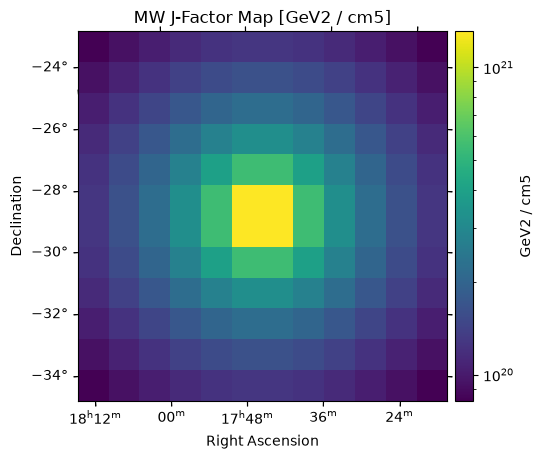

In [6]:
jfactor_map = jfactory.compute_jfactor_map(factor=factor)

ax = jfactor_map.plot(cmap="viridis", norm=LogNorm(), add_cbar=True)
ax.set_title(f"MW J-Factor Map [{jfactor_map.unit}]")
plt.show()

To obtain the total D/J-Factor in a region, one can simply sum the values of the pixels in that region.

In [7]:
# J(10°)
radius = 5*u.deg
sky_reg = CircleSkyRegion(center = center, radius = radius)
pix_reg = sky_reg.to_pixel(wcs = geom.wcs)

total_jfactor = pix_reg.to_mask().multiply(jfactor_map.quantity).sum()
print(
    f"J-factor within {radius} radius is {total_jfactor:.3g}"
)

J-factor within 5.0 deg radius is 2.48e+22 GeV2 / cm5


## Direct Estimate

One can also consider to compute directly the J/D-Factor not using a map and giving to the `compute_jfactor` method the integration bounds. This will give an estimate of the J/D-Factor values. 

In [64]:
# avoiding the phi_min = 0 otherwise the integral does not converge for a NFW profile
jfactor_estimate = jfactory.compute_jfactor(
    factor= factor,
    phi_min = 0.1*u.deg, phi_max = 5*u.deg,
    theta = 2*np.pi*u.rad
)

jfactor_estimate

<Quantity 2.55831504e+22 GeV2 / cm5>

## Large Magellanic Cloud

In [8]:
center_LMC = SkyCoord(80.9, -69.8, frame="icrs", unit="deg")
center_dis_LMC = 50.1 * u.kpc
radius_LMC = 6.4 * u.kpc

# a geometry centered on the LMC
geom_LMC = WcsGeom.create(
    binsz=binsz, skydir=center_LMC, width=width, frame="icrs"
)

# Density profile
r_s_LMC=12.6 * u.kpc
rho_s_LMC = ((2.6 * 10**6 * u.solMass / u.kpc**3)*const.c**2).to("u.GeV/(u.cm**3)")
profile_LMC = NFWProfile(r_s=r_s_LMC, rho_s=rho_s_LMC)

jfactory_LMC = NewJFactory(
    profile=profile_LMC,
    center_dis=center_dis_LMC,
    r_min=0*u.cm,# or center_dis - radius_LMC,
    r_max=center_dis_LMC + radius_LMC,
    geom=geom_LMC,
    lon_0=center_LMC.ra,
    lat_0=center_LMC.dec,
)

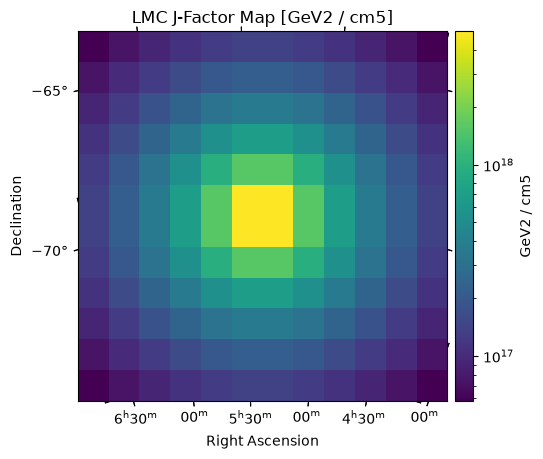

In [9]:
jfactor_map_LMC = jfactory_LMC.compute_jfactor_map(factor=factor)

ax = jfactor_map_LMC.plot(cmap="viridis", norm=LogNorm(), add_cbar=True)
ax.set_title(f"LMC J-Factor Map [{jfactor_map_LMC.unit}]")
plt.show()

In [10]:
# J(10°)
radius = 5*u.deg
sky_reg_LMC = CircleSkyRegion(center = center_LMC, radius = radius)
pix_reg_LMC = sky_reg_LMC.to_pixel(wcs = geom_LMC.wcs)

total_jfactor_LMC = pix_reg_LMC.to_mask().multiply(jfactor_map_LMC.quantity).sum()
print(
    f"J-factor within {radius} radius is {total_jfactor_LMC:.3g}"
)

J-factor within 5.0 deg radius is 5.93e+19 GeV2 / cm5


## MW + LMC
Summing the contribution of the J-Factor of the two DM halos on a map centered on the LMC. 

This is done assuming that the two DM halos are independent of each each other. If it is not the case, there is an element missing due to the $2 \times \rho_{\rm MW} \times \rho_{\rm LMC}$ missing factor. The method always works for D-Factors sums. 

Adding the $2 \times \rho_{\rm MW} \times \rho_{\rm LMC}$ missing factor is always possible using the JFactory for a profile equal to $\sqrt{2 \times \rho_{\rm MW} \times \rho_{\rm LMC}}$

Now, using the independent-halo approximation, we first compute the MW J-Factor in the LMC geom

In [11]:
jfactory_MW = NewJFactory(
    profile=profile,
    center_dis=center_dis,
    r_min= 0 * u.cm,
    r_max= center_dis + virial_radius,
    geom=geom_LMC,
    lon_0=center.ra,
    lat_0=center.dec,
)

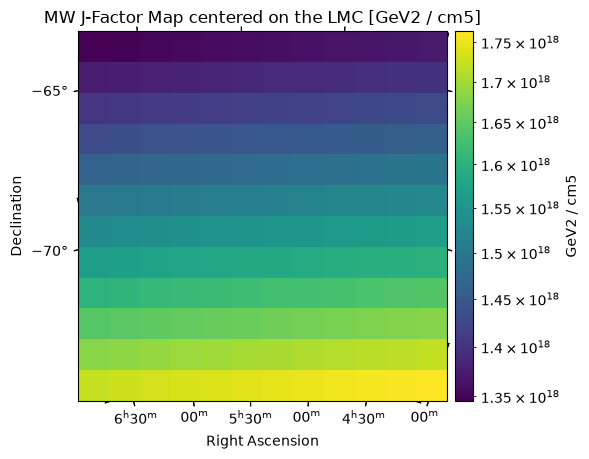

In [12]:
jfactor_map_MW = jfactory_MW.compute_jfactor_map(factor=factor)

ax = jfactor_map_MW.plot(cmap="viridis", norm=LogNorm(), add_cbar=True)
ax.set_title(f"MW J-Factor Map centered on the LMC [{jfactor_map_MW.unit}]")
plt.show()

Then we can sum the two maps

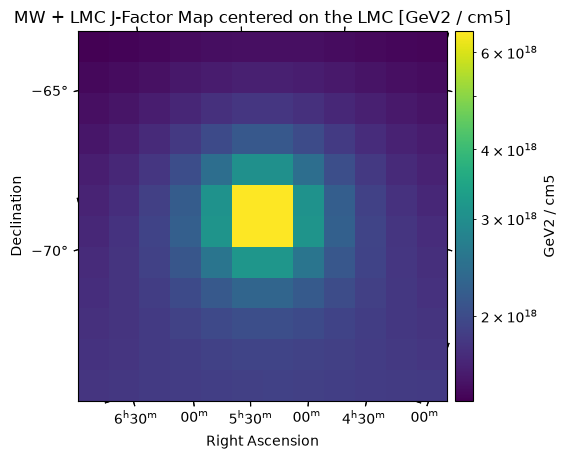

In [13]:
jfactor_map_sum = jfactor_map_LMC + jfactor_map_MW

ax = jfactor_map_sum.plot(cmap="viridis", norm=LogNorm(), add_cbar=True)
ax.set_title(f"MW + LMC J-Factor Map centered on the LMC [{jfactor_map_sum.unit}]")
plt.show()

In [14]:
# J(10°)
radius = 5*u.deg
sky_reg_LMC = CircleSkyRegion(center = center_LMC, radius = radius)
pix_reg_LMC = sky_reg_LMC.to_pixel(wcs = geom_LMC.wcs)

total_jfactor_sum = pix_reg_LMC.to_mask().multiply(jfactor_map_sum.quantity).sum()
print(
    f"J-factor within {radius} radius is {total_jfactor_sum:.3g}"
)

J-factor within 5.0 deg radius is 1.82e+20 GeV2 / cm5


## Spatial and Sky model

In [51]:
total_jfactor = jfactor_map_sum.quantity.sum()

spatial_model = TemplateSpatialModel(
    map=jfactor_map_sum,
    normalize=True,
)

spectral_model = DarkMatterSpectralModel(
    mDM=10 * u.TeV,
    channel="b",
    factor=total_jfactor,
    annihilation=True,
)

DM_model = SkyModel(
    spatial_model=spatial_model,
    spectral_model=spectral_model,
    name="DM-Model",
)

DM_model

The filename is not defined. Therefore, the model will not be serialised correctly. To set the filename, the "template_model.filename" attribute can be used.

Since Gammapy v2.2, the default source has changed from 'pppc4' to 'cosmixs'.

The filename is not defined. Therefore, the model will not be serialised correctly. To set the filename, the "template_model.filename" attribute can be used.


SkyModel(spatial_model=<gammapy.modeling.models.spatial.TemplateSpatialModel object at 0x7f0228788e90>, spectral_model=<gammapy.astro.darkmatter.spectra.DarkMatterSpectralModel object at 0x7f02291e2a80>)temporal_model=None)

In [56]:
DM_model.evaluate(
    center_LMC.ra,
    center_LMC.dec,
    1 * u.TeV,
).to("cm-2 s-1 TeV-1 sr-1")

<Quantity [2.66485455e-13] 1 / (TeV s sr cm2)>

## Points to review

- If the map has a central pixel this method does not work and the centered pixel will need a separate treatment.
- An error on the integration and the effect of the appoximation is not evaluated
- Add a method to easily compute the $2 \times \rho_{\rm MW} \times \rho_{\rm LMC}$ missing value for more sub-halos and structures